<a href="https://colab.research.google.com/github/Axaxxa/6005-portfolio-/blob/main/6005_week3%2Bportfolio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

KNN

In [72]:
#Import initial libraries and dataset

import numpy as np
import pandas as pd

df=pd.read_csv('sample_data/titanic (1).csv')
df.head()

,PassengerId,Pclass,Name,Sex,Age,Ticket,Fare,Survived
0,1,3,"Braund, Mr. Owen Harris",male,22.0,A/5 21171,7.2500,0
1,2,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,PC 17599,71.2833,1
2,3,3,"Heikkinen, Miss. Laina",female,26.0,STON/O2. 3101282,7.9250,1
3,4,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,113803,53.1000,1
4,5,3,"Allen, Mr. William Henry",male,35.0,373450,8.0500,0


In [73]:
#Number of rows and columns in dataset (rows, columns)
df.shape

(891, 8)

In [74]:
#Finding the number of missing values for each feature
df.isnull().sum()


,0
PassengerId,0
Pclass,0
Name,0
Sex,0
Age,177
Ticket,0
Fare,0
Survived,0


In [75]:
#finding and replacing the missing values with mean of non-null values of age
df['Age']=df['Age'].replace(np.nan,df['Age'].mean())
df['Age'][:10]


,Age
0,22.000000
1,38.000000
2,26.000000
3,35.000000
4,35.000000
5,29.699118
6,54.000000
7,2.000000
8,27.000000
9,14.000000


In [76]:
#encoding categorical data to numerical:
Gender = {"Sex":{"male": 0, "female": 1}}
df = df.replace(Gender)
df.head()

/tmp/ipykernel_4624/303628042.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.replace(Gender)


,PassengerId,Pclass,Name,Sex,Age,Ticket,Fare,Survived
0,1,3,"Braund, Mr. Owen Harris",0,22.0,A/5 21171,7.2500,0
1,2,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,38.0,PC 17599,71.2833,1
2,3,3,"Heikkinen, Miss. Laina",1,26.0,STON/O2. 3101282,7.9250,1
3,4,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,35.0,113803,53.1000,1
4,5,3,"Allen, Mr. William Henry",0,35.0,373450,8.0500,0


In [77]:
# drop some irrelevant features

df.drop(['Name', 'PassengerId', 'Ticket', 'Embarked', 'Cabin'], axis=1, inplace=True, errors='ignore')
df.head()

,Pclass,Sex,Age,Fare,Survived
0,3,0,22.0,7.2500,0
1,1,1,38.0,71.2833,1
2,3,1,26.0,7.9250,1
3,1,1,35.0,53.1000,1
4,3,0,35.0,8.0500,0


In [78]:
# Split the dataset into input and target features

X=df.drop('Survived', axis=1)
y=df.Survived

In [136]:
# Split the input and target features into training and testing set
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=16)

In [139]:
from sklearn.neighbors import KNeighborsClassifier

# 1. Ensure the training and test data are numerically encoded safely
gender_map = {'male': 0, 'female': 1}
if X_train['Sex'].dtype == 'object':
    X_train['Sex'] = X_train['Sex'].map(gender_map)
if X_test['Sex'].dtype == 'object':
    X_test['Sex'] = X_test['Sex'].map(gender_map)

# 2. Fill any remaining missing values in Age with the training mean
X_train['Age'] = X_train['Age'].fillna(X_train['Age'].mean())
X_test['Age'] = X_test['Age'].fillna(X_train['Age'].mean())

# create knn classifier
knn = KNeighborsClassifier(n_neighbors = 3)

# fit the data
knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

In [140]:
#make prediction
y_pred=knn.predict(X_test)

In [142]:
from sklearn.metrics import accuracy_score,confusion_matrix

knn_accuracy = round(accuracy_score(y_test, y_pred), 4)
print("Accuarcy",knn_accuracy*100)

Accuarcy 70.95


In [143]:
#Confusion matrix
print(confusion_matrix(y_test,y_pred))

[[87 20]
 [32 40]]


Logistic regression


In [114]:
import pandas as pd; import numpy as np
import seaborn as sns
df=pd.read_csv('sample_data/titanic (1).csv')
df.head()

,PassengerId,Pclass,Name,Sex,Age,Ticket,Fare,Survived
0,1,3,"Braund, Mr. Owen Harris",male,22.0,A/5 21171,7.2500,0
1,2,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,PC 17599,71.2833,1
2,3,3,"Heikkinen, Miss. Laina",female,26.0,STON/O2. 3101282,7.9250,1
3,4,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,113803,53.1000,1
4,5,3,"Allen, Mr. William Henry",male,35.0,373450,8.0500,0


In [85]:
##Separating features and the target
# Let's separate features and the target in X and Y respectively.
X = df.drop(columns=['Survived', 'Name', 'PassengerId', 'Ticket', 'Cabin', 'Embarked'], errors='ignore')
Y = df['Survived']
print("Features (X):")
print(X.head())
print("Target (Y):")
print(y.head())


Features (X):
   Pclass     Sex   Age     Fare
0       3    male  22.0   7.2500
1       1  female  38.0  71.2833
2       3  female  26.0   7.9250
3       1  female  35.0  53.1000
4       3    male  35.0   8.0500
Target (Y):
0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64


In [86]:
print(df.shape)
print(df.info())
print(df['Survived'].value_counts())

(891, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Pclass       891 non-null    int64  
 2   Name         891 non-null    object 
 3   Sex          891 non-null    object 
 4   Age          714 non-null    float64
 5   Ticket       891 non-null    object 
 6   Fare         891 non-null    float64
 7   Survived     891 non-null    int64  
dtypes: float64(2), int64(3), object(3)
memory usage: 55.8+ KB
None
Survived
0    549
1    342
Name: count, dtype: int64


In [92]:
# split X and y into training and testing sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=16)

In [93]:
# Preprocess the datasets to handle missing values and encode categorical features
# 1. Fill missing values in Age with the mean
X_train['Age'] = X_train['Age'].fillna(X_train['Age'].mean())
X_test['Age'] = X_test['Age'].fillna(X_train['Age'].mean())  # Use training mean to avoid data leakage

# 2. Convert 'Sex' to numeric
gender_map = {'male': 0, 'female': 1}
X_train['Sex'] = X_train['Sex'].map(gender_map)
X_test['Sex'] = X_test['Sex'].map(gender_map)

# import the class
from sklearn.linear_model import LogisticRegression

# instantiate the model (using the default parameters)
logreg = LogisticRegression(multi_class='ovr')

# fit the model with data
logreg.fit(X_train, y_train)
print("Training Accuracy:", logreg.score(X_train, y_train))

# predict the response for new observations
y_pred = logreg.predict(X_test)
print("Testing Accuracy:", logreg.score(X_test, y_test))

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(


Training Accuracy: 0.8075842696629213
Testing Accuracy: 0.7597765363128491


In [94]:
from sklearn import metrics

cnf_matrix = metrics.confusion_matrix(y_test, y_pred)
cnf_matrix

array([[92, 15],
       [28, 44]])

Text(0.5, 427.9555555555555, 'Predicted label')

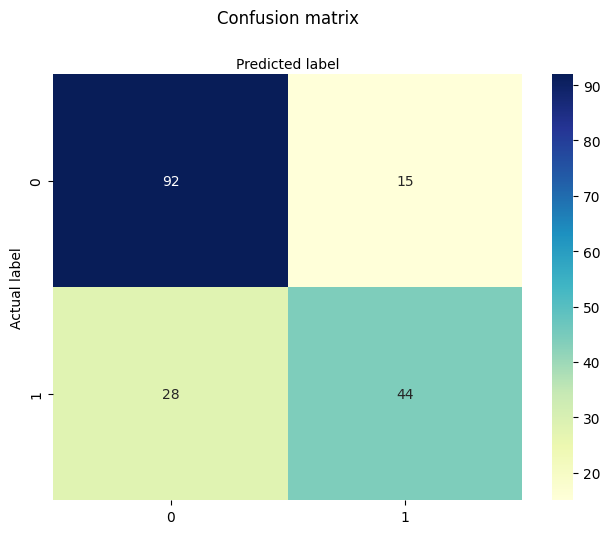

In [95]:
# import required modules
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

class_names=[0,1] # name  of classes
fig, ax = plt.subplots()
tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names)
plt.yticks(tick_marks, class_names)
# create heatmap
sns.heatmap(pd.DataFrame(cnf_matrix), annot=True, cmap="YlGnBu" ,fmt='g')
ax.xaxis.set_label_position("top")
plt.tight_layout()
plt.title('Confusion matrix', y=1.1)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')

In [98]:
from sklearn.metrics import classification_report
target_names = ['0', '1',]
print(classification_report(y_test, y_pred, target_names=target_names))

              precision    recall  f1-score   support

           0       0.77      0.86      0.81       107
           1       0.75      0.61      0.67        72

    accuracy                           0.76       179
   macro avg       0.76      0.74      0.74       179
weighted avg       0.76      0.76      0.75       179



In [102]:
logreg.predict_proba(X_test)[:2]

array([[0.22359146, 0.77640854],
       [0.52860873, 0.47139127]])